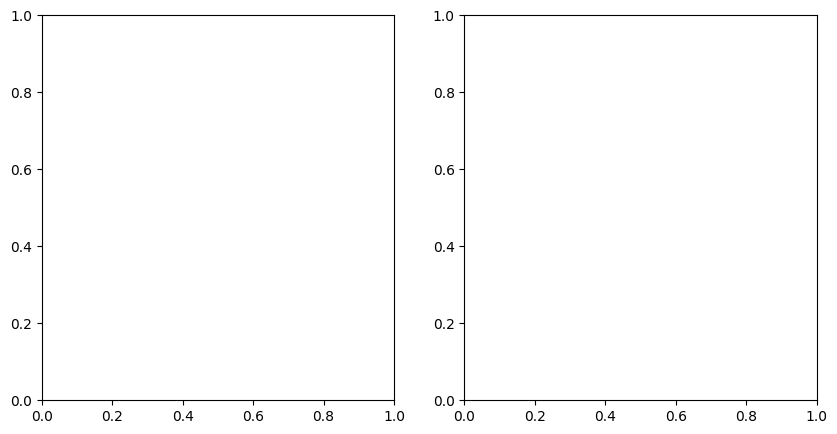

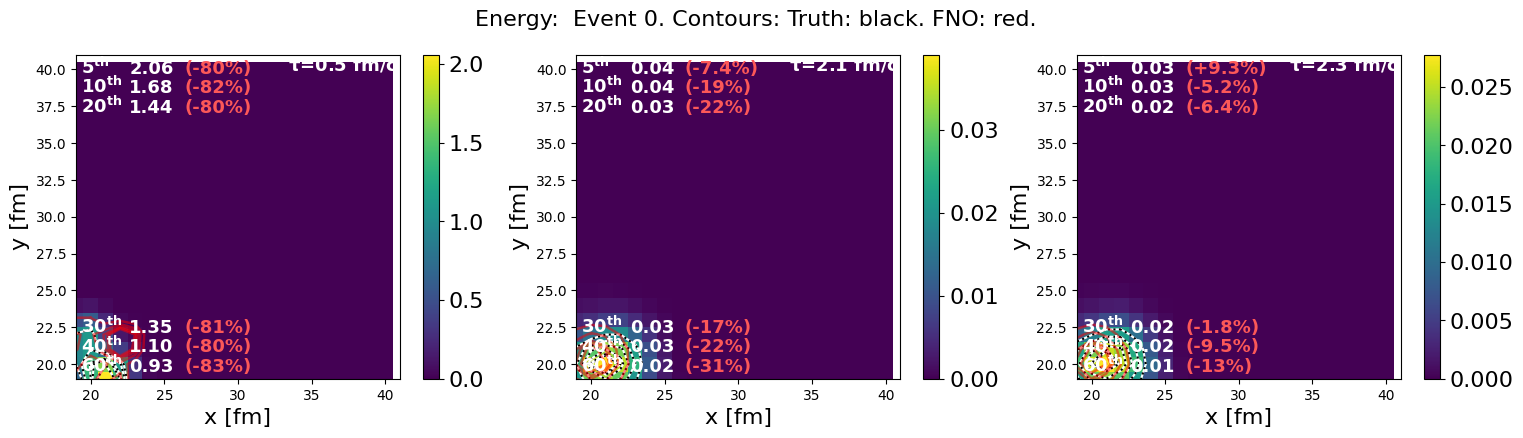

In [ ]:
import numpy as np 
import awkward as ak
import uproot as up
import matplotlib.pyplot as plt

import numpy as np 
import matplotlib.pyplot as plt
from collections import namedtuple
from skimage.measure import find_contours

from skinnycontour import plot_three_bins_contour

# def get_topcdf_value(X, cdf_ratio):
#     '''
#     input: X: tensor, cdf_ratio: float in 0..1
#     output: float
#     Return the value of the cdf_ratio-th percentile of the
#     values in X
#     '''
#     # Flatten the tensor
#     flat_X = X.flatten()
    
#     # Sort the flattened tensor
#     sorted_X = np.sort(flat_X)[::-1]
    
#     # Calculate the cumulative sum
#     cumulative_sum = np.cumsum(sorted_X)
    
#     # Find the threshold value for the top cdfval
#     total_sum = cumulative_sum[-1]
#     threshold_index = np.searchsorted(cumulative_sum, cdf_ratio * total_sum)
    
#     return sorted_X[threshold_index]


# def draw_contour_lines(dat, *,  rescale=None, val=None, cdfrat=None, linestyle='dashed',color='red',linewidth=1, styles=[],alpha=1):
#     '''
#     input: mask: tensor
#     output: None
#     Draw dotted lines around the values that are True in
#     the mask
#     '''
#     if val is None and cdfrat is None:
#         raise ValueError('Either val or cdfrat must be specified')

#     if val is None:
#         val = get_topcdf_value(dat, cdfrat)

#     contours = find_contours(dat, level=val)
#     if rescale:
#         try:
#             contours[0] = contours[0]*rescale
#         except:
#             print('failed to find contrours for rescale')
    
#     if styles:
#         for n, contour in enumerate(contours):
#             for linestyle, color, linewidth in styles:
#                 plt.plot(contour[:, 1], contour[:, 0], linestyle=linestyle, color=color, linewidth=linewidth, alpha=alpha)
#     else:
#         for n, contour in enumerate(contours):
#             plt.plot(contour[:, 1], contour[:, 0], linestyle=linestyle, color=color, linewidth=linewidth, alpha=alpha)

#     return val


# def plot_contour(P: np.ndarray, # predicted 2D array
#                  T: np.ndarray, # truth 2D array 
#                  cdfrats = [0.05,.1,.2,.3,.4,.6],
#                  axis: plt.Axes = None, # if none, create new figure
#                  xlim: tuple = (15, 45),
#                  ylim: tuple = None, # default to xlim
#                  tau: float = 0.6,
#                  #topadjust=0.85, 
#                  #tag='', 
#                  show_FNO=True, 
#                  show_cdflines=True, 
#                  show_cdfvals=True, 
#                  # fn=None, 
#                  rescale=None, 
#                  title='',
#                  save=None):

#     if axis is None:
#         fig, axis = plt.subplots(1, 1, figsize=(4.5, 4.5))

#     dat_truth = T
#     dat_model = P

#     axis.imshow(dat_truth, origin='lower', cmap='viridis', extent=(0, 60, 0, 60))
#     plt.sca(axis)

#     # Rescale tick marks
#     if ylim == (15, 45):
#         ticks = np.arange(15, 50, 5)  # Original tick positions
#         new_labels = ticks / 2  # Rescale the labels
#         axis.set_xticks(ticks)
#         axis.set_xticklabels(new_labels)
#         axis.set_yticks(ticks)
#         axis.set_yticklabels(new_labels)
#         plt.sca(axis)
#         axis.tick_params(axis='both', which='major', length=8, width=2, labelsize=15)
#         axis.tick_params(axis='both', which='minor', length=5, width=1)
#     elif ylim == (0, 60):
#         ticks = np.arange(0, 61, 10)
#         new_labels = ticks / 2  # Rescale the labels
#         axis.set_xticks(ticks)
#         axis.set_xticklabels(new_labels)
#         axis.set_yticks(ticks)
#         axis.set_yticklabels(new_labels)
#         plt.sca(axis)

#     cnt = 0
#     xcntl = 0.015
#     xcnt = {0: xcntl, 1: xcntl, 2: xcntl, 3: xcntl, 4: xcntl, 5: xcntl}
#     ycnt = {0: 0.93, 1: 0.87, 2: 0.81, 3: 0.13, 4: 0.07, 5: 0.01}

#     tcolor = "#a9e4f3"  # lighter red

#     axis.text( 
#         0.655,
#         0.94,
#         r'$\mathbf{\tau}$'+f'={tau:.1f} '+r'fm/$\mathbf{c}$',
#         color='white',
#         fontsize=13,
#         ha='left',
#         va='bottom',
#         transform=axis.transAxes,
#         bbox=dict(facecolor='black', alpha=0.0, edgecolor='none'),
#         usetex=False,
#         fontstyle='normal',
#         fontweight='bold'
#     )

#     if show_cdflines:
#         Tvals = []
#         cnt = 0
#         # draw truth lines first, and then the model lines
#         for cdf in cdfrats:
#             Tval=draw_contour_lines(dat_truth, rescale=rescale, cdfrat=cdf, color=tcolor, linestyle='solid', styles=[('solid', 'white', 1.5),('dotted','black',1.5)])
#             Tvals.append(Tval)

#             if show_cdfvals:
#                 textw = f'{Tval:4.2f}'

#                 axis.text(
#                     xcnt[cnt],
#                     ycnt[cnt],
#                     f"{int(cdf*100):.0f}$^{{\\mathbf{{th}}}}$",
#                     color='white',
#                     fontsize=13,
#                     ha='left',
#                     va='bottom',
#                     transform=axis.transAxes,
#                     bbox=dict(facecolor='black', alpha=0.0, edgecolor='none'),
#                     usetex=False,
#                     fontstyle='normal',
#                     fontweight='bold'
#                 )
#                 axis.text(
#                     xcnt[cnt]+0.15,
#                     ycnt[cnt],
#                     textw,
#                     color='white',
#                     fontsize=13,
#                     fontweight='bold',
#                     ha='left',
#                     va='bottom',
#                     transform=axis.transAxes,
#                     bbox=dict(facecolor='black', alpha=0.0, edgecolor='none')
#                 )
#                 cnt += 1

#         if show_FNO:
#             for n, Tval in enumerate(Tvals):
#                 cdf = cdfrats[n]

#                 Pval = draw_contour_lines(dat_model, rescale=rescale, cdfrat=cdf, color='red', linestyle='solid',linewidth=1.8, alpha=0.5)
#                 # title += f'\n{cdf*100:2.0f}%: P={Pval:5.3f}'
#                 delta = Pval - Tval
#                 drat = (delta / Tval)*100
#                 if abs(drat) < 1.:
#                     textp = f'{drat:.2f}'
#                 elif abs(drat) < 10:
#                     textp = f'{drat:.1f}'
#                 else:
#                     textp = f'{drat:.0f}'
#                 if drat < 0:
#                     textp = f'({textp}%)'
#                 else:
#                     textp = f'(+{textp}%)'

#                 axis.text(
#                     xcnt[n]+0.32,
#                     ycnt[n],
#                     textp,
#                     color="#fc5858",  # lighter red
#                     fontsize=13,
#                     fontweight='bold',
#                     ha='left',
#                     va='bottom',
#                     transform=axis.transAxes,
#                     bbox=dict(facecolor='black', alpha=0.0, edgecolor='none')
#                 )

#         axis.set_title(title)
#         if ylim:
#             axis.set_ylim(ylim)
#         if xlim:
#             axis.set_xlim(xlim)
#         axis.set_xlabel('x [fm]')
#         axis.set_ylabel('y [fm]', fontsize=16)
#         axis.set_xlabel('x [fm]', fontsize=16)
#         cbar = plt.colorbar(axis.images[0], ax=axis)
#         cbar.ax.tick_params(labelsize=16)
#         # plt.colorbar(axes[i].imagesg[0], ax=axes[i])


# def plot_three_bins_contour (P, T, iparam=0, event=0, tau0=0.5, taudelta=0.1, iT=(0, 25, 48),
#     cdfrats=[0.05,.1,.2,.3,.4,.6], ylim=(15,45), xlim=(15,45),
#     topadjust=0.85, 
#     tag='', show_FNO=True, show_cdflines=True, 
#     show_cdfvals=True, fn=None, rescale=None, save=None, fig=None, axes=None, ieta=0,
#     taulabel_offset=0):

#     if show_cdfvals and not show_FNO:
#       raise ValueError('show_FNO requires show_cdfvals to be True')

#     if iparam == 0:
#         tag = f'Energy: {tag}'
#     elif iparam == 1:
#         tag = f'Vy: {tag}'
#     elif iparam == 2:
#         tag = f'Vx: {tag}'
#     elif iparam == 3:
#         tag = f'Vz: {tag}'

#     if axes is None:
#         fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.5))

#     assert len(iT) == 3

#     for i, iT in enumerate(iT):
#         title = ''

#         if len(dat.shape) == 5:
#             print('fixme am')
#             dat_truth = T[event,iparam,:,:,iT]
#             dat_model = P[event,iparam,:,:,iT]
#         else:
#             dat_truth = T[event, iparam, :,:, ieta, iT]
#             dat_model = P[event, iparam, :,:, ieta, iT]

#         if fn is not None:
#             dat_truth = fn(dat_truth, iT)
#             dat_model = fn(dat_model, iT)
        
#         plot_contour(dat_model, dat_truth, cdfrats=cdfrats, axis=axes[i], xlim=xlim, ylim=ylim, title=title, tau=tau0 + iT*taudelta,
#                      show_FNO=show_FNO, show_cdflines=show_cdflines, show_cdfvals=show_cdfvals,
#                      rescale=rescale)

#         continue

#     plt.tight_layout(pad=2.0, w_pad=0.0, h_pad=0.0)
#     plt.subplots_adjust(hspace=.00)
#     plt.subplots_adjust(wspace=.1)
#     plt.subplots_adjust(top=0.88)
#     plt.subplots_adjust(bottom=0.16)  # Add space at the bottom for x-axis labels2
#     plt.subplots_adjust(left=0.05)  # Add space at the bottom for x-axis labels2

#     fig.suptitle(f'{tag} Event {event}. Contours: Truth: black. FNO: red.', fontsize=16)
#     if save:
#         fig.savefig(save)
#     plt.show()

def load_event(file_name, tree_name, branch_name, ievent):
    with up.open(file_name) as file:
        tree = file[tree_name]
        branch = tree[branch_name]
        event_data = branch.array(library="ak", entry_start=ievent, entry_stop=ievent + 1)[0].to_numpy()
        nx = file['nx'].member('fVal')
        ny = file['ny'].member('fVal')
        neta = file['neta'].member('fVal')
        nFeatures = file['nFeatures'].member('fVal')
        dat_len = nx * ny * neta * nFeatures
        nevents = len(event_data) // dat_len
        arr = event_data.reshape((nevents, nx, ny, neta, nFeatures))
        arr = np.moveaxis(arr, -1, 1)
        arr = np.moveaxis(arr, 0, -1)
    return arr

if __name__ == "__main__":
    # file_name = "/home/davidstewart/xscape-docker/X-SCAPE/build/dAu_seed5_5k_10cen.root"
    file_name = "/home/putschke/Hydro_Data/dAu_500ev_b_lt_2fm.root"
    tree_name = 't'
    branch_name = 'user_res'

    datA = load_event(file_name, tree_name, branch_name, ievent=4)
    datB = load_event(file_name, tree_name, branch_name, ievent=6)
    datA = datA[np.newaxis, ...]  # add batch dimension
    datB = datB[np.newaxis, ...]  # add batch dimension
    # dat = np.moveaxis(dat, -2, 1)
    # plt.imshow(dat[0,:,:,2,30], aspect='auto', origin='lower')

    
    # print(dat[3,:,:,2,40])
    # for i in range(4):
        # print([i,np.sum(dat[3,:,:,i,44])])
    # print(type(dat))

    fig, axis = plt.subplots(1, 2, figsize=(10, 5))
    # plot_contour(dat[0,0,:,:,2,22], dat[0,0,:,:,2,21], ylim=(19,41), xlim=(19,41), axis=axis[1],title='This stage')
    # plt.show()
    plot_three_bins_contour(datA, datB, iparam=0, event=0, iT=(0,16,18), ylim=(19,41), xlim=(19,41), fig=fig, show_FNO=True, show_cdflines=True, show_cdfvals=True)